# ETL v2: grilla espacial y variables por celda

Este notebook corre el ETL v2 definido en `src/etl.py` con los parámetros de `config.yaml`, y muestra los controles de calidad y una primera mirada al tamaño de celda. Se ejecuta desde la raíz del repositorio; también se puede correr sin notebook con `python -m src.etl`.

**Cambios respecto de la v1** (`01_spatial_data_processing.ipynb`):

- Celdas completas con el origen alineado a múltiplos del tamaño (sin `gpd.clip`). Las grillas de 125, 250, 500 y 1000 m quedan anidadas y las celdas del borde ya no son más chicas; `frac_dentro` indica qué parte de cada celda cae dentro de la ciudad.
- Puntos asignados a su celda por índice (`(x - x0) // tamaño`) en vez de `sjoin`.
- Variable objetivo de conteo: `n_supermercados`.
- Variables nuevas de accesibilidad y uso de suelo: `largo_vias_m`, `dist_via_principal_m` y `frac_residencial`.
- Salida en Parquet con coordenadas (`ix`, `iy`, `x`, `y`), necesarias para las variables de entorno y la validación espacial.
- Gran Concepción pasa de 6 a 9 comunas (se agregan Coronel, Lota y Tomé).
- Controles de calidad que detienen la corrida si un supermercado, paradero o habitante queda sin celda.

La corrida completa lee `chile.gpkg` (1,4 GB) una vez por ciudad, así que toma varios minutos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import etl

cfg = etl.cargar_config("config.yaml")
print(f"Extracto OSM: {cfg['osm_fecha_descarga']}")
print(f"Tamaños de celda: {cfg['grilla']['tamanos_m']} m (principal: {cfg['grilla']['tamano_principal_m']} m)")
for prefijo, ciudad in cfg["ciudades"].items():
    print(f"{ciudad['nombre']}: {len(ciudad['comunas'])} comunas")

Extracto OSM: 2026-10-02
Tamaños de celda: [125, 250, 500, 1000] m (principal: 250 m)
Gran Santiago: 39 comunas
Gran Concepción: 9 comunas


## 1. Corrida completa

Para cada ciudad se arma la máscara comunal, se extraen las capas de OSM y los centroides de manzana del Censo 2024, y se construye una tabla por tamaño de celda en `data/processed/celdas_<ciudad>_<tamaño>m.parquet`. La grilla de 250 m también se corre desplazada 125 m (`_d125`) para el análisis de sensibilidad. Las capas intermedias quedan en `data/interim/` y el resumen en `resultados/etl_v2/resumen_tamanos.csv`.

In [2]:
resumen = etl.ejecutar(cfg)

[15:51:49] Leyendo cartografía censal...
[15:51:51] Gran Santiago: máscara de 39 comunas
[15:51:51] Gran Santiago: extrayendo capas OSM
[15:52:04] Gran Santiago: 524 supermercados, 12416 paraderos, 8396 POI, 6,532,737 habitantes
[15:58:37]   125 m: 592,306 celdas, 510 con supermercado (12 con 2 o más) -> data\processed\celdas_stgo_125m.parquet
[16:00:24]   250 m: 148,932 celdas, 490 con supermercado (28 con 2 o más) -> data\processed\celdas_stgo_250m.parquet
[16:00:51]   500 m: 37,661 celdas, 438 con supermercado (67 con 2 o más) -> data\processed\celdas_stgo_500m.parquet
[16:00:58]   1000 m: 9,623 celdas, 330 con supermercado (121 con 2 o más) -> data\processed\celdas_stgo_1000m.parquet
[16:02:41]   250 m desplazada: 148,927 celdas, 489 con supermercado (33 con 2 o más) -> data\processed\celdas_stgo_250m_d125.parquet
[16:02:41] Gran Concepción: máscara de 9 comunas
[16:02:41] Gran Concepción: extrayendo capas OSM
[16:02:48] Gran Concepción: 159 supermercados, 2460 paraderos, 1497 POI,

## 2. Primera mirada al tamaño de celda

- `pct_celdas_con_super_que_tienen_2mas`: qué tan seguido una celda tiene más de un supermercado. Si es bajo a 250 m, el conteo y la versión binaria casi coinciden a ese tamaño.
- `pct_celdas_con_super_sin_poblacion`: supermercados en celdas sin habitantes. Muestra por qué el filtro de celdas inhabitables debe usar una distancia X y no solo "celda poblada".

In [ ]:
columnas = [
    "celdas", "celdas_pobladas", "supermercados", "celdas_con_super", "celdas_con_2mas",
    "pct_celdas_con_super_que_tienen_2mas", "pct_celdas_con_super_sin_poblacion",
]
resumen.set_index(["ciudad", "tamano_m", "desfase_m"])[columnas]

celdas  celdas_pobladas  supermercados  \
ciudad tamano_m desfase_m                                           
stgo   125      0.0        592306            24289            524   
       250      0.0        148932             9585            524   
       500      0.0         37661             3232            524   
       1000     0.0          9623             1065            524   
       250      125.0      148927             9642            524   
ccp    125      0.0         98542             5370            159   
       250      0.0         25233             2317            159   
       500      0.0          6580              883            159   
       1000     0.0          1783              338            159   
       250      125.0       25211             2311            159   

                           celdas_con_super  celdas_con_2mas  \
ciudad tamano_m desfase_m                                      
stgo   125      0.0                     510               12   
       250      0.0                     490               28   
       500      0.0                     438               67   
       1000     0.0                     330              121   
       250      125.0                   489               33   
ccp    125      0.0                     152                6   
       250      0.0                     138               17   
       500      0.0                     112               33   
       1000     0.0                      80               40   
       250      125.0                   141               15   

                           pct_celdas_con_super_que_tienen_2mas  \
ciudad tamano_m desfase_m                                         
stgo   125      0.0                                         2.4   
       250      0.0                                         5.7   
       500      0.0                                        15.3   
       1000     0.0                                        36.7   
       250      125.0                                       6.7   
ccp    125      0.0                                         3.9   
       250      0.0                                        12.3   
       500      0.0                                        29.5   
       1000     0.0                                        50.0   
       250      125.0                                      10.6   

                           pct_celdas_con_super_sin_poblacion  
ciudad tamano_m desfase_m                                      
stgo   125      0.0                                      50.4  
       250      0.0                                      15.1  
       500      0.0                                       3.4  
       1000     0.0                                       1.2  
       250      125.0                                    13.5  
ccp    125      0.0                                      44.1  
       250      0.0                                      15.2  
       500      0.0                                       3.6  
       1000     0.0                                       0.0  
       250      125.0                                    12.1

## 3. Comparación con la v1 (250 m)

Las cifras cambian por tres motivos esperados: la grilla ahora usa celdas completas que tocan la máscara, Gran Concepción suma tres comunas y la variable objetivo cuenta supermercados en vez de marcar presencia.

In [4]:
tablas = {c: pd.read_parquet(f"{cfg['rutas']['processed']}/celdas_{c}_250m.parquet") for c in cfg["ciudades"]}

for c, t in tablas.items():
    nombre = cfg["ciudades"][c]["nombre"]
    print(f"{nombre} v2: {len(t):,} celdas, {t['n_supermercados'].sum()} supermercados "
          f"en {(t['n_supermercados'] > 0).sum()} celdas, {t['poblacion_celda'].sum():,} habitantes")
    try:
        v1 = pd.read_csv(f"{cfg['rutas']['processed']}/dataset_entrenamiento_{c}.csv")
        print(f"{nombre} v1: {len(v1):,} celdas, {int(v1['target_supermercado'].sum())} celdas con supermercado, "
              f"{v1['densidad_poblacion'].sum():,.0f} habitantes")
    except FileNotFoundError:
        pass

tablas["stgo"].describe().T.round(2)

Gran Santiago v2: 148,932 celdas, 524 supermercados en 490 celdas, 6,532,737 habitantes
Gran Santiago v1: 148,911 celdas, 486 celdas con supermercado, 6,532,737 habitantes
Gran Concepción v2: 25,233 celdas, 159 supermercados en 138 celdas, 954,408 habitantes
Gran Concepción v1: 10,501 celdas, 120 celdas con supermercado, 742,804 habitantes


,count,mean,std,min,25%,50%,75%,max
tamano_m,148932.0,250.00,0.00,250.0,250.00,250.0,250.00,250.0
desfase_m,148932.0,0.00,0.00,0.0,0.00,0.0,0.00,0.0
ix,148932.0,253.91,113.55,0.0,162.00,265.0,349.00,460.0
iy,148932.0,328.23,133.86,0.0,236.00,345.0,431.00,595.0
x,148932.0,376852.14,28388.64,313375.0,353875.00,379625.0,400625.00,428375.0
y,148932.0,6287182.74,33465.86,6205125.0,6264125.00,6291375.0,6312875.00,6353875.0
frac_dentro,148932.0,0.99,0.09,0.0,1.00,1.0,1.00,1.0
n_supermercados,148932.0,0.00,0.06,0.0,0.00,0.0,0.00,5.0
conteo_paraderos,148932.0,0.08,0.46,0.0,0.00,0.0,0.00,9.0
conteo_convenience,148932.0,0.01,0.17,0.0,0.00,0.0,0.00,8.0


## 4. Mapa de control

Población por celda (escala logarítmica) y celdas con al menos un supermercado, solo para celdas pobladas o con supermercado. Sirve para revisar a ojo que la grilla, el censo y OSM calcen.

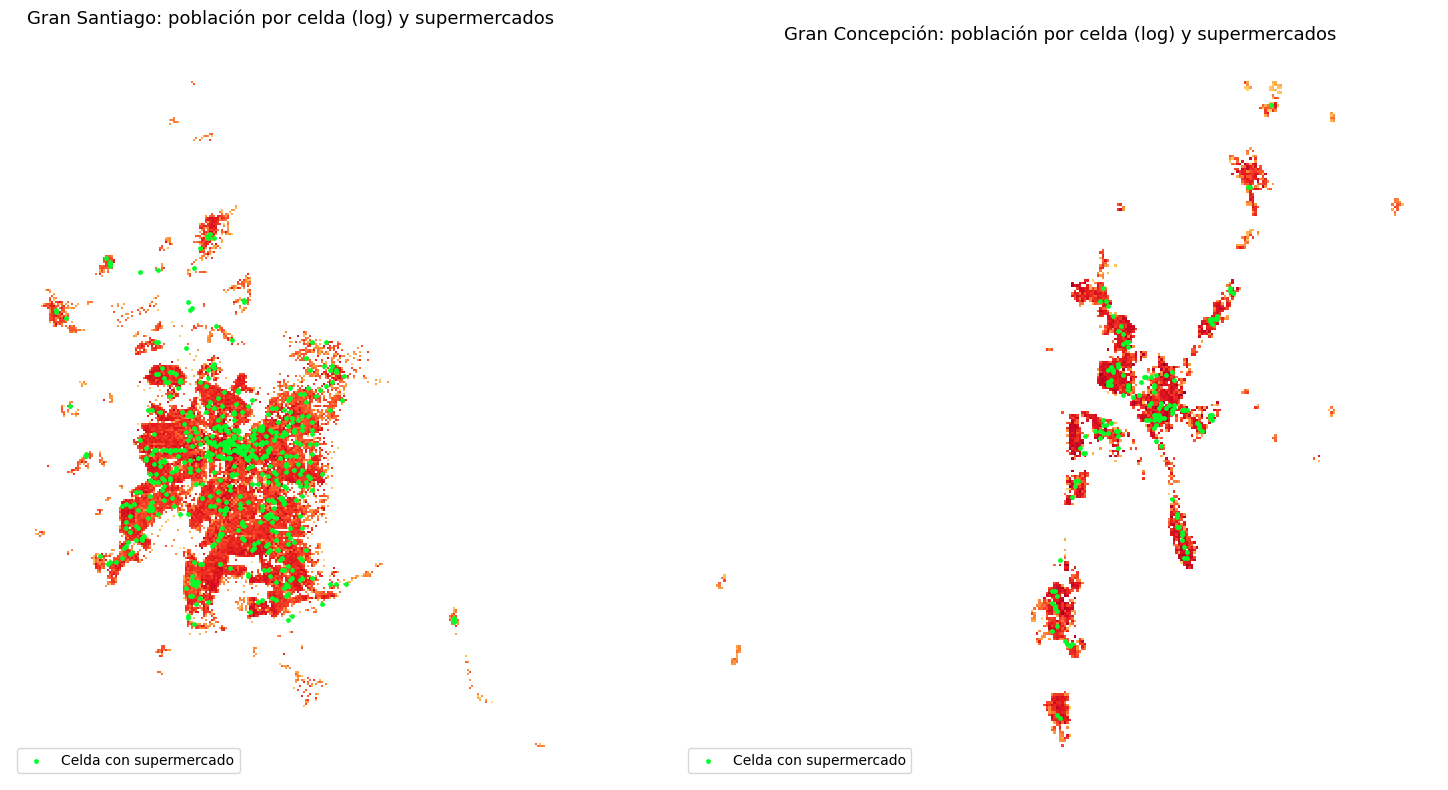

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 8))
for (c, t), ax in zip(tablas.items(), ejes):
    visibles = etl.geometria_celdas(t[(t["poblacion_celda"] > 0) | (t["n_supermercados"] > 0)])
    visibles.plot(column=np.log1p(visibles["poblacion_celda"]), cmap="YlOrRd", linewidth=0, ax=ax)
    con_super = visibles[visibles["n_supermercados"] > 0]
    ax.scatter(con_super["x"], con_super["y"], s=6, color="#00ff2a", label="Celda con supermercado")
    ax.set_title(f"{cfg['ciudades'][c]['nombre']}: población por celda (log) y supermercados", fontsize=13)
    ax.set_axis_off()
    ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(f"{cfg['rutas']['resultados']}/mapa_control_250m.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

## 5. Diccionario de variables

| Columna | Descripción |
| --- | --- |
| `id_celda` | Identificador estable: `<ciudad>_<tamaño>_<ix>_<iy>` |
| `ciudad`, `tamano_m`, `desfase_m` | Ciudad (`stgo`, `ccp`), lado de la celda en metros y desplazamiento de la grilla |
| `ix`, `iy` | Columna y fila de la celda en la grilla |
| `x`, `y` | Centro de la celda en metros (UTM, ver `crs_utm`) |
| `frac_dentro` | Fracción de la celda dentro de la máscara comunal (1 = completa) |
| `n_supermercados` | **Variable objetivo**: supermercados OSM en la celda |
| `conteo_paraderos` | Paraderos y estaciones (`bus_stop`, `bus_station`, `station`) |
| `conteo_<categoría>` | Puntos de interés OSM por categoría (almacenes, malls, farmacias, ferias, colegios, universidades, institutos, hospitales, clínicas, recintos deportivos) |
| `poblacion_celda` | Personas del Censo 2024 cuyo centroide de manzana cae en la celda |
| `largo_vias_m` | Metros de vías `primary`, `secondary`, `tertiary` y `trunk` dentro de la celda |
| `dist_via_principal_m` | Distancia del centro de la celda a la vía `primary` o `trunk` más cercana |
| `frac_residencial` | Fracción del área de la celda con uso de suelo residencial en OSM |
| `crs_utm` | Sistema de coordenadas de `x` e `y` |